In [6]:
using IonSim

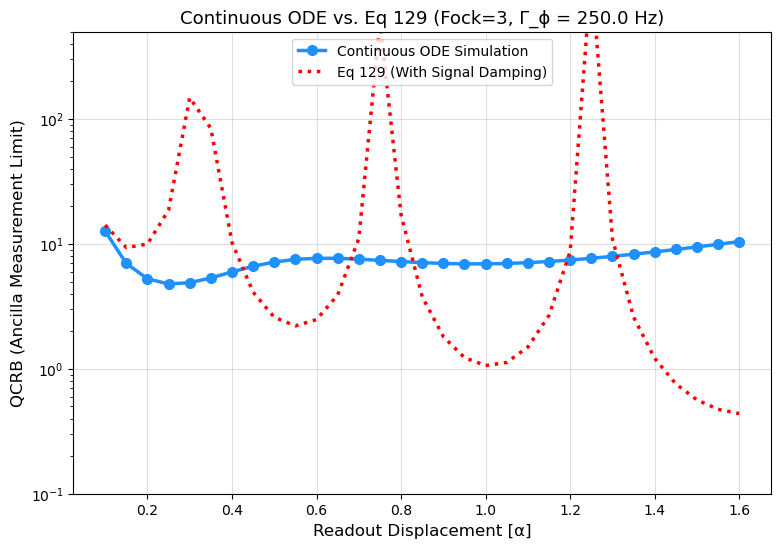

 EXECUTING CONTINUOUS MASTER EQUATION (ODE)
 Integrating 62 dynamic ODEs...


In [1]:
ENV["MPLBACKEND"] = "agg"
using PyPlot
using QuantumOptics
using LinearAlgebra

function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0; L_prev1 = 1.0 - x; L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1; L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(rho1, rho2, d_beta::Float64; tol=1e-10)
    drho_data = (dense(rho2).data - dense(rho1).data) / d_beta
    λ, V = LinearAlgebra.eigen(Hermitian(dense(rho1).data))
    
    qfi = 0.0
    n_dim = length(λ)
    for i in 1:n_dim
        for j in 1:n_dim
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    return qfi > 0 ? 1.0 / qfi : Inf
end

# -------------------------------------------------------------
# Exact Continuous Master Equation Solver
# -------------------------------------------------------------
function simulate_continuous_protocol(alpha::Float64, beta_val::Float64, n_fock::Int, gamma_phi_hz::Float64, t_sig_us::Float64)
    b_spin = SpinBasis(1//2)
    b_mot = FockBasis(45) 

    spin_plus = normalize(spindown(b_spin) + spinup(b_spin))
    psi_init = spin_plus ⊗ fockstate(b_mot, n_fock)

    Pe = spinup(b_spin) ⊗ dagger(spinup(b_spin))
    Pg = spindown(b_spin) ⊗ dagger(spindown(b_spin))
    
    # CRITICAL FIX: Alpha must be imaginary to be orthogonal to the real beta drive!
    U_sdf = (Pe ⊗ displace(b_mot, 1im * alpha)) + (Pg ⊗ displace(b_mot, -1im * alpha))
    rho_split = dm(U_sdf * psi_init)

    # Beta drive is on the real axis
    H_drive = identityoperator(b_spin) ⊗ (1im * (beta_val / t_sig_us) * (create(b_mot) - destroy(b_mot)))
    
    gamma_phi_us = gamma_phi_hz * 1e-6
    J_dephase = identityoperator(b_spin) ⊗ (sqrt(gamma_phi_us) * number(b_mot))
    
    f_dyn(t, rho) = (H_drive, [J_dephase], [dagger(J_dephase)])
    
    _, sol = timeevolution.master_dynamic([0.0, t_sig_us], rho_split, f_dyn, reltol=1e-8, abstol=1e-10)
    
    # Reverse SDF Recombination (Also using imaginary alpha)
    U_sdf_rev = (Pe ⊗ displace(b_mot, -1im * alpha)) + (Pg ⊗ displace(b_mot, 1im * alpha))
    rho_recombined = U_sdf_rev * sol[end] * dagger(U_sdf_rev)
    
    return ptrace(rho_recombined, 2)
end

function plot_qcrb_master_vs_theory(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi_hz::Float64=250.0)
    g_rad = 453.17 
    t_sig_s = 2.0 / g_rad
    t_sig_us = t_sig_s * 1e6
    Gamma_t = gamma_phi_hz * t_sig_s
    
    beta_base = 1.0
    d_beta = 1e-3
    
    alphas = collect(0.1:0.05:1.6)
    sim_qcrbs = Float64[]
    theory_eq129_qcrbs = Float64[]
    
    println("==================================================")
    println(" EXECUTING CONTINUOUS MASTER EQUATION (ODE)")
    println("==================================================")
    println(" Integrating $(length(alphas) * 2) dynamic ODEs...")
    
    for a in alphas
        rho_spin_base = simulate_continuous_protocol(a, beta_base, n_fock, gamma_phi_hz, t_sig_us)
        rho_spin_pert = simulate_continuous_protocol(a, beta_base + d_beta, n_fock, gamma_phi_hz, t_sig_us)
        
        qcrb_sim = calculate_qcrb(rho_spin_base, rho_spin_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)
        
        # CRITICAL FIX: Add the continuous signal-damping term!
        signal_damping_factor = (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0))
        
        V_eq129 = exp(-2 * a^2) * laguerre(n_fock, 4 * a^2)
        
        # The QCRB denominator now includes the squared damping factor
        denominator = 16.0 * a^2 * (signal_damping_factor^2) * V_eq129^2
        push!(theory_eq129_qcrbs, 1.0 / denominator)
    end
    
    # Plotting
    fig = figure(figsize=(9, 6))
    
    plot(alphas, sim_qcrbs, "o-", markersize=7, color="dodgerblue", linewidth=2.5, label="Continuous ODE Simulation")
    plot(alphas, theory_eq129_qcrbs, "r:", linewidth=2.5, label="Eq 129 (With Signal Damping)")

    yscale("log")
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Continuous ODE vs. Eq 129 (Fock=$n_fock, Γ_ϕ = $gamma_phi_hz Hz)", fontsize=13)
    
    legend(fontsize=10, loc="upper center")
    grid(alpha=0.4)
    ylim(1e-1, 5e2)
    
    display(fig)
    println("==================================================")
end

plot_qcrb_master_vs_theory(3, 1e3, 250.0)

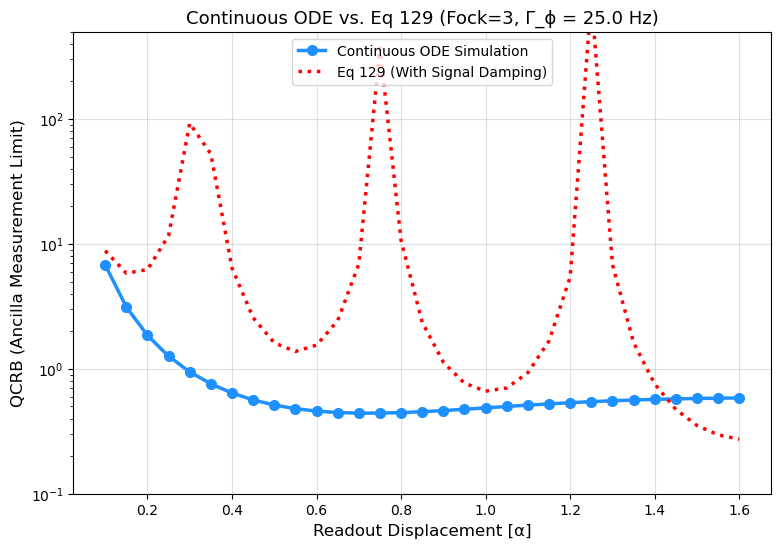

 EXECUTING CONTINUOUS MASTER EQUATION (ODE)
 Integrating 62 dynamic ODEs...


In [2]:
plot_qcrb_master_vs_theory(3, 1e3, 25.0)

In [7]:
function SDF_apply_with_alpha(laser_intensity = 1e4, angle = 0, target_alpha = 0.716, cat_state = false, initial_state = nothing, fock_state_n = 0, n_th_set = 10000.0, gamma_0_set = 1e-2)

    # ---------------------------------------------------------
    # 1. Common Trap InitializationQ
    # ---------------------------------------------------------
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))

    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]

    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]

    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    # ---------------------------------------------------------
    # 2. Physics Calculation
    # ---------------------------------------------------------
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    # ---------------------------------------------------------
    # 3. SEQUENCE EXECUTION
    # ---------------------------------------------------------
    if cat_state
        # =========================================================
        # PERFECT OPERATOR MATH: Alpha Readout (No readout noise)
        # =========================================================
        alpha_complex = target_alpha * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
        
    else
        # =========================================================
        # CONTINUOUS LINDBLAD DISPLACEMENT: Beta Signal (With Noise)
        # =========================================================
        I_spin = identityoperator(ion["g"].basis)  
        n_th = n_th_set           
        gamma_0 = gamma_0_set  
    
        gamma_plus_us = (gamma_0 * n_th) * 1e-6 
        gamma_minus_us = (gamma_0 * (n_th + 1)) * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)

        # CRITICAL FIX: Lock the simulation time to the beta=1.0 baseline.
        # This guarantees identical ODE grid steps for finite difference.
        baseline_beta = 1.0 
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

     H_m = (1im * target_alpha / target_time_us) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op

        # PURE DEPHASING JUMP OPERATOR
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end


        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        
        # We only need the start and end points for the solver now
        tspan_sdf = [0.0, target_time_us]

        println("Simulating pure continuous Beta displacement with Lindblad noise...")
        # Added strict tolerances to completely eliminate numerical ODE phase drift
        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-10, abstol=1e-12)

        return sol_beta[end]
    end
end

SDF_apply_with_alpha (generic function with 9 methods)

In [8]:
SDF_apply_with_alpha(3, 1e3, 250.0)

UndefVarError: UndefVarError: `n_op` not defined in `Main`
Suggestion: check for spelling errors or missing imports.


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


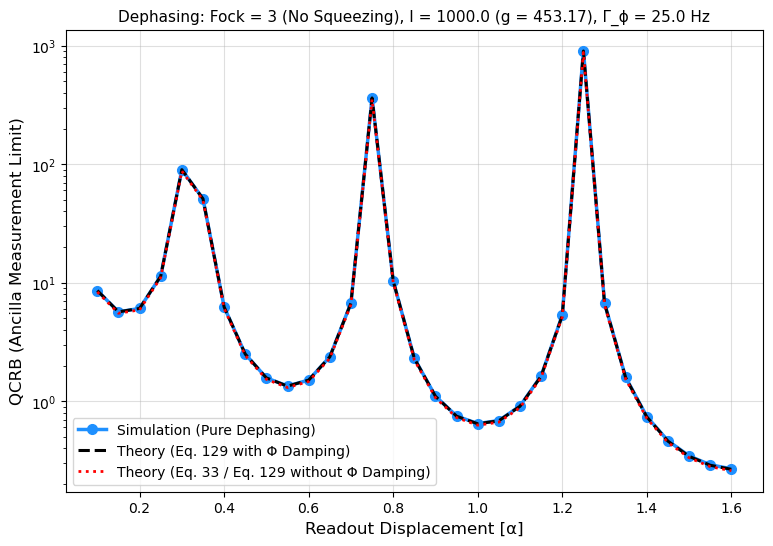

In [12]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    # 1. Promote pure states (Ket) to density matrices
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    
    # 2. Extract dense data
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data

    # 3. Finite difference derivative
    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    
    # 4. Use Hermitian() to guarantee real eigenvalues
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb # Fixed: returns 2-tuple (qfi, qcrb)
end

function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0, target_alpha = 0.716, cat_state = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2)
    # 1. Common Trap Initialization
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    # 2. Physics Calculation
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    # 3. SEQUENCE EXECUTION
    if cat_state
        # PERFECT OPERATOR MATH: Alpha Readout (No readout noise)
        alpha_complex = target_alpha * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
        
    else
        # CONTINUOUS LINDBLAD DISPLACEMENT: Beta Signal (PURE DEPHASING)
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        
        # PURE DEPHASING GENERATOR: Number operator n = a^dag a
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        baseline_beta = 1.0 
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        H_m = (1im * target_alpha / target_time_us) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op

        # PURE DEPHASING JUMP OPERATOR
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        tspan_sdf = [0.0, target_time_us]

        println("Simulating continuous Beta displacement with Pure Dephasing...")
        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-10, abstol=1e-12)

        return sol_beta[end]
    end
end

function get_qcrb_coordinates_dephasing(n_fock::Int=0, laser_intensity::Float64=1e3, gamma_phi::Float64=1e-2)
    beta_signal = 1.0
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    B_field = 1e-13
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    # Calculate exact t_sig for the theoretical phase damping factor
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_z = (2 * π / transition_λ) / sqrt(2)
    eta = k_z * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    Omega_eff = Omega_eff_Hz * 2 * π
    t_sig_s = (2 * beta_signal) / (eta * Omega_eff)
    Gamma_t = gamma_phi * t_sig_s

    b_fock = FockBasis(50) 
    initial_m_qo = fockstate(b_fock, n_fock)
    initial_m_sim = Ket(sim_mode, initial_m_qo.data)
    initial_sys = normalize(ion["g"]) ⊗ initial_m_sim

    println("\nRunning master equation for Base β Signal...")
    noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys, n_fock, gamma_phi)
    
    println("\nRunning master equation for Perturbed β Signal (+ d_beta)...")
    noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys, n_fock, gamma_phi)

    alphas = collect(0.1:0.05:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]
    theory_eq129_phi_qcrbs = Float64[]

    # Phase damping factor from continuous laser drive
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    println("\nSweeping α readout (generating coordinates)...")
    for a in alphas
        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        # 1. CLOSED SYSTEM BASELINE (Also equals Eq. 129 without Φ damping for r=0)
        exp_term_closed = 4 * a^2 
        numerator_closed = exp(exp_term_closed)
        L_val_closed = laguerre(n_fock, 4 * a^2)
        denominator_closed = 16 * a^2 * (L_val_closed^2)
        qcrb_closed = numerator_closed / denominator_closed
        push!(theory_closed_qcrbs, qcrb_closed)

        # 2. EQ. 129 WITH Φ PHASE DAMPING TERM
        qcrb_eq129_phi = qcrb_closed / (continuous_signal_factor^2)
        push!(theory_eq129_phi_qcrbs, qcrb_eq129_phi)
    end

    return alphas, sim_qcrbs, theory_closed_qcrbs, theory_eq129_phi_qcrbs
end

function plot_qcrb_results_dephasing(n_fock::Int=0, laser_intensity::Float64=1e3, gamma_phi::Float64=1e-2)
    x_alpha, y_sim, y_theory_closed, y_theory_eq129_phi = get_qcrb_coordinates_dephasing(n_fock, laser_intensity, gamma_phi)

    # Recompute coupling rate g for title
    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_z = (2 * π / transition_λ) / sqrt(2)
    eta = k_z * z_zpf
    
    k_vec = (x̂ + ẑ) / √2; ϵ_vec = ŷ
    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    g_display = round((eta * Omega_eff_Hz * 2 * π) / 2.0, digits=2)

    fig = figure(figsize=(9, 6))
    
    plot(x_alpha, y_sim, "o-", markersize=7, color="dodgerblue", linewidth=2.5, label="Simulation (Pure Dephasing)")
    plot(x_alpha, y_theory_eq129_phi, "k--", linewidth=2.2, label="Theory (Eq. 129 with Φ Damping)")
    plot(x_alpha, y_theory_closed, "r:", linewidth=2, label="Theory (Eq. 33 / Eq. 129 without Φ Damping)")

    yscale("log")
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Dephasing: Fock = $(n_fock) (No Squeezing), I = $(laser_intensity) (g = $(g_display)), Γ_ϕ = $(gamma_phi) Hz", fontsize=11)
    
    legend(fontsize=10)
    grid(alpha=0.4)
    
    display(fig)
end

# Compare at 250.0 Hz (or 25.41 Hz)
plot_qcrb_results_dephasing(3, 1e3, 25.0)


Running master equation for Base β Signal...
Simulating continuous Beta displacement with Pure Dephasing...

Running master equation for Perturbed β Signal (+ d_beta)...
Simulating continuous Beta displacement with Pure Dephasing...

Sweeping α readout (generating coordinates)...


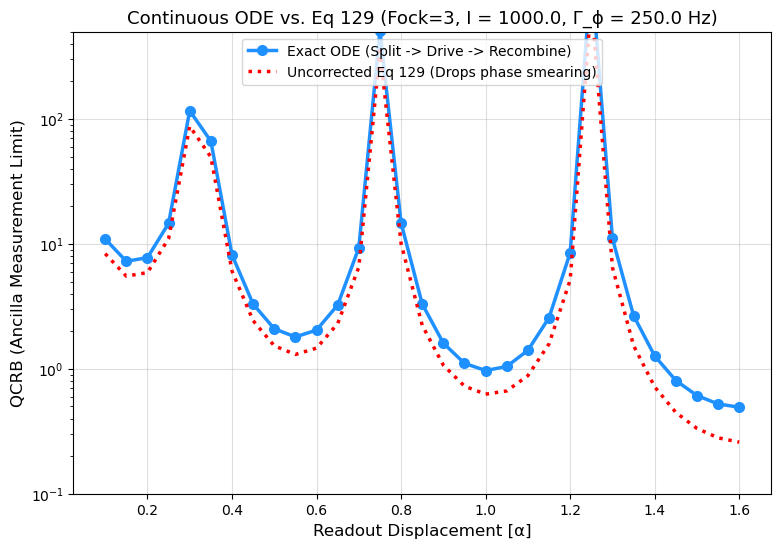

In [13]:
plot_final_comparison(3, 1e3, 250.0)


Sweeping α (running master_dynamic with f_dyn on each α-displaced state)...


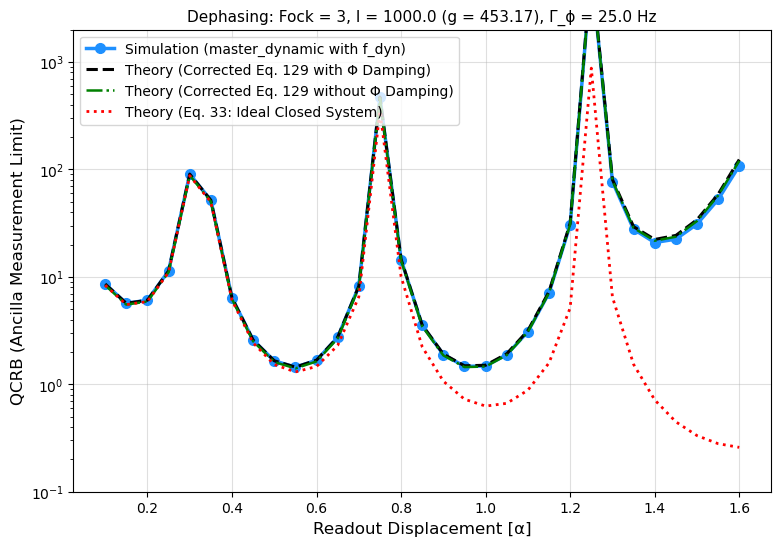

In [14]:
ENV["MPLBACKEND"] = "agg"
using IonSim
using QuantumOptics
using PyPlot
using LinearAlgebra

function laguerre(n::Int, x::Float64)
    if n == 0 return 1.0 end
    if n == 1 return 1.0 - x end
    L_prev2 = 1.0
    L_prev1 = 1.0 - x
    L_curr = 0.0
    for k in 1:(n-1)
        L_curr = ((2k + 1 - x) * L_prev1 - k * L_prev2) / (k + 1)
        L_prev2 = L_prev1
        L_prev1 = L_curr
    end
    return L_curr
end

function calculate_qcrb(state, state_perturbed, d_alpha::Float64; tol=1e-10)
    rho1 = isa(state, Ket) ? dm(state) : state
    rho2 = isa(state_perturbed, Ket) ? dm(state_perturbed) : state_perturbed
    
    rho_dense_data = dense(rho1).data
    rho_pert_dense_data = dense(rho2).data

    drho_data = (rho_pert_dense_data - rho_dense_data) / d_alpha
    λ, V = LinearAlgebra.eigen(Hermitian(rho_dense_data))
    
    qfi = 0.0
    n = length(λ)
    for i in 1:n
        for j in 1:n
            if real(λ[i] + λ[j]) > tol
                @views v_i = V[:, i]
                @views v_j = V[:, j]
                drho_ij = dot(v_i, drho_data * v_j)
                qfi += 2 * (abs(drho_ij)^2) / real(λ[i] + λ[j])
            end
        end
    end
    
    qcrb = qfi > 0 ? 1.0 / qfi : Inf
    return qfi, qcrb
end

function SDF_apply_with_alpha_dephasing(laser_intensity = 1e4, angle = 0, target_alpha = 0.716, cat_state = false, initial_state = nothing, fock_state_n = 0, gamma_phi_set = 1e-2)
    trap_freq = 19e5 
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    
    mode_z = zmodes(chain)[1] 
    mode_z.N = 50
    mode_z.shape = [51]
    
    k_vec = (x̂ + ẑ) / √2
    ϵ_vec = ŷ
    B_field = 1e-13
    
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    mode = zmodes(trap_pre)[1]
    
    ψ_ion = normalize(ion["g"])
    ψ_mode = fockstate(mode, fock_state_n)
    ψ_initial = initial_state !== nothing ? initial_state : (ψ_ion ⊗ ψ_mode)

    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_total = 2 * π / transition_λ
    k_z = k_total / sqrt(2)
    eta = k_z * z_zpf

    dummy_laser = Laser(I=laser_intensity, k=k_vec, ϵ=ϵ_vec, λ=transition_λ)
    Bhat_tuple = (; x=0.0, y=0.0, z=1.0)
    
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), Bhat_tuple)
    Omega_eff = Omega_eff_Hz * 2 * π

    if cat_state
        alpha_complex = target_alpha * exp(1im * angle)
        g = ion["g"]
        e = ion["e"]
        
        x_plus = normalize(g + e)
        x_minus = normalize(g - e)
        
        P_plus = x_plus ⊗ dagger(x_plus)
        P_minus = x_minus ⊗ dagger(x_minus)
        
        D_plus = IonSim.displace(mode, alpha_complex)
        D_minus = IonSim.displace(mode, -alpha_complex)
        
        U_SDF = (P_plus ⊗ D_plus) + (P_minus ⊗ D_minus)
        
        if isa(ψ_initial, Operator)
            return U_SDF * ψ_initial * dagger(U_SDF)
        else
            return U_SDF * ψ_initial
        end
    else
        I_spin = identityoperator(ion["g"].basis)  
        gamma_phi_us = gamma_phi_set * 1e-6 

        temp_fock_basis = FockBasis(mode.N) 
        a_op = DenseOperator(mode, mode, QuantumOptics.destroy(temp_fock_basis).data)
        at_op = DenseOperator(mode, mode, QuantumOptics.create(temp_fock_basis).data)
        n_op = DenseOperator(mode, mode, QuantumOptics.number(temp_fock_basis).data)

        baseline_beta = 1.0 
        target_time_s = (2 * baseline_beta) / (eta * Omega_eff)
        target_time_us = target_time_s * 1e6

        H_m = (1im * target_alpha / target_time_us) * (exp(1im * angle) * at_op - exp(-1im * angle) * a_op)
        H_sys = I_spin ⊗ H_m

        n_sys = I_spin ⊗ n_op
        J_dephase = sqrt(gamma_phi_us) * n_sys
        J_ops = [J_dephase]
        J_ops_dag = dagger.(J_ops)

        function f_dyn(time_t, rho_state)
            return (H_sys, J_ops, J_ops_dag)
        end

        rho_initial = isa(ψ_initial, Ket) ? dm(ψ_initial) : ψ_initial
        tspan_sdf = [0.0, target_time_us]

        _, sol_beta = timeevolution.master_dynamic(tspan_sdf, rho_initial, f_dyn, reltol=1e-9, abstol=1e-11)

        return sol_beta[end]
    end
end

function get_qcrb_coordinates_dephasing(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=25.0)
    # Local signal perturbation around β = 0 (with t_sig locked to baseline_beta = 1.0)
    beta_signal = 0.0
    d_beta = 1e-4 
    
    trap_freq = 19e5 
    hbar = 1.0545718e-34       
    amu = 1.66053906e-27       
    m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    B_field = 1e-13
    trap_pre = Chamber(iontrap=chain, B=B_field, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    sim_mode = zmodes(trap_pre)[1]
    sim_mode.N = 50
    sim_mode.shape = [51]

    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    k_z = (2 * π / transition_λ) / sqrt(2)
    eta = k_z * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    Omega_eff = Omega_eff_Hz * 2 * π
    t_sig_s = (2 * 1.0) / (eta * Omega_eff)
    Gamma_t = gamma_phi * t_sig_s

    N_cut = 50
    b_fock = FockBasis(N_cut) 
    psi_fock_qo = fockstate(b_fock, n_fock)
    spin_g = normalize(ion["g"])

    alphas = collect(0.1:0.05:1.6)
    sim_qcrbs = Float64[]
    theory_closed_qcrbs = Float64[]
    theory_eq129_no_phi_qcrbs = Float64[]
    theory_eq129_with_phi_qcrbs = Float64[]

    # Continuous laser drive phase damping factor from Φ
    continuous_signal_factor = Gamma_t > 1e-10 ? (2.0 / Gamma_t) * (1.0 - exp(-Gamma_t / 2.0)) : 1.0

    println("\nSweeping α (running master_dynamic with f_dyn on each α-displaced state)...")
    for a in alphas
        # ---------------------------------------------------------
        # 1. SIMULATION (master_dynamic with f_dyn at displacement α)
        # ---------------------------------------------------------
        psi_disp_qo = QuantumOptics.displace(b_fock, -1im * a) * psi_fock_qo
        initial_sys_a = spin_g ⊗ Ket(sim_mode, psi_disp_qo.data)

        noisy_beta_state = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal, false, initial_sys_a, n_fock, gamma_phi)
        noisy_beta_state_pert = SDF_apply_with_alpha_dephasing(laser_intensity, 0.0, beta_signal + d_beta, false, initial_sys_a, n_fock, gamma_phi)

        state_a_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state, n_fock, gamma_phi)
        state_a_pert_full = SDF_apply_with_alpha_dephasing(laser_intensity, pi/2, a, true, noisy_beta_state_pert, n_fock, gamma_phi)

        rho_spin_a = ptrace(state_a_full, 2)
        rho_spin_a_pert = ptrace(state_a_pert_full, 2)
        
        _, qcrb_sim = calculate_qcrb(rho_spin_a, rho_spin_a_pert, d_beta)
        push!(sim_qcrbs, qcrb_sim)

        # ---------------------------------------------------------
        # 2. REVISED EQ. 128-129 THEORY (Using c_j(α) = <j|D(α)|n>)
        # ---------------------------------------------------------
        # c_j(α) c_k^*(α) * exp(-0.5 * Gamma_t * (j - k)^2)
        rho_theory = dm(QuantumOptics.displace(b_fock, a) * psi_fock_qo)
        for i in 1:(N_cut + 1)
            for j in 1:(N_cut + 1)
                rho_theory.data[i, j] *= exp(-0.5 * Gamma_t * ((i - 1) - (j - 1))^2)
            end
        end
        # V_open = sum_{j,k} c_j(α) c_k^*(α) e^{-0.5 Γ t (j-k)^2} <k|D(-2α)|j>
        V_open = real(expect(QuantumOptics.displace(b_fock, -2.0 * a), rho_theory))

        qcrb_no_phi = 1.0 / (16.0 * a^2 * V_open^2)
        qcrb_with_phi = 1.0 / (16.0 * a^2 * (continuous_signal_factor^2) * V_open^2)

        push!(theory_eq129_no_phi_qcrbs, qcrb_no_phi)
        push!(theory_eq129_with_phi_qcrbs, qcrb_with_phi)

        # ---------------------------------------------------------
        # 3. CLOSED SYSTEM BASELINE (Eq. 33)
        # ---------------------------------------------------------
        qcrb_closed = exp(4 * a^2) / (16 * a^2 * (laguerre(n_fock, 4 * a^2)^2))
        push!(theory_closed_qcrbs, qcrb_closed)
    end

    return alphas, sim_qcrbs, theory_closed_qcrbs, theory_eq129_no_phi_qcrbs, theory_eq129_with_phi_qcrbs
end

function plot_qcrb_results_dephasing(n_fock::Int=3, laser_intensity::Float64=1e3, gamma_phi::Float64=25.0)
    x_alpha, y_sim, y_closed, y_eq129_no_phi, y_eq129_phi = get_qcrb_coordinates_dephasing(n_fock, laser_intensity, gamma_phi)

    trap_freq = 19e5; hbar = 1.0545718e-34; amu = 1.66053906e-27; m_Ca40 = 39.96259 * amu    
    ion = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
    chain = LinearChain(ions=[ion], comfrequencies=(x=3e6, y=3e6, z=trap_freq), selectedmodes=(; z=[1]))
    trap_pre = Chamber(iontrap=chain, B=1e-13, Bhat=ẑ)
    transition_λ = transitionwavelength(ion, ("g", "e"), trap_pre)
    omega_trap = 2 * π * trap_freq
    z_zpf = sqrt(hbar / (2 * m_Ca40 * omega_trap))
    eta = ((2 * π / transition_λ) / sqrt(2)) * z_zpf
    dummy_laser = Laser(I=laser_intensity, k=(x̂ + ẑ) / √2, ϵ=ŷ, λ=transition_λ)
    Omega_eff_Hz = IonSim.matrixelement(ion, ("g", "e"), laser_intensity, polarization(dummy_laser), wavevector(dummy_laser), (; x=0.0, y=0.0, z=1.0))
    g_display = round((eta * Omega_eff_Hz * 2 * π) / 2.0, digits=2)

    fig = figure(figsize=(9, 6))
    
    plot(x_alpha, y_sim, "o-", markersize=7, color="dodgerblue", linewidth=2.5, label="Simulation (master_dynamic with f_dyn)")
    plot(x_alpha, y_eq129_phi, "k--", linewidth=2.2, label="Theory (Corrected Eq. 129 with Φ Damping)")
    plot(x_alpha, y_eq129_no_phi, "g-.", linewidth=1.8, label="Theory (Corrected Eq. 129 without Φ Damping)")
    plot(x_alpha, y_closed, "r:", linewidth=2.0, label="Theory (Eq. 33: Ideal Closed System)")

    yscale("log")
    ylim(1e-1, 2e3)
    xlabel("Readout Displacement [α]", fontsize=12)
    ylabel("QCRB (Ancilla Measurement Limit)", fontsize=12)
    title("Dephasing: Fock = $(n_fock), I = $(laser_intensity) (g = $(g_display)), Γ_ϕ = $(gamma_phi) Hz", fontsize=11)
    
    legend(fontsize=10, loc="upper left")
    grid(alpha=0.4)
    
    display(fig)
end

# Run at Γ_ϕ = 25.0 Hz (or 250.0 Hz to see the Φ damping separation clearly)
plot_qcrb_results_dephasing(3, 1e3, 25.0)

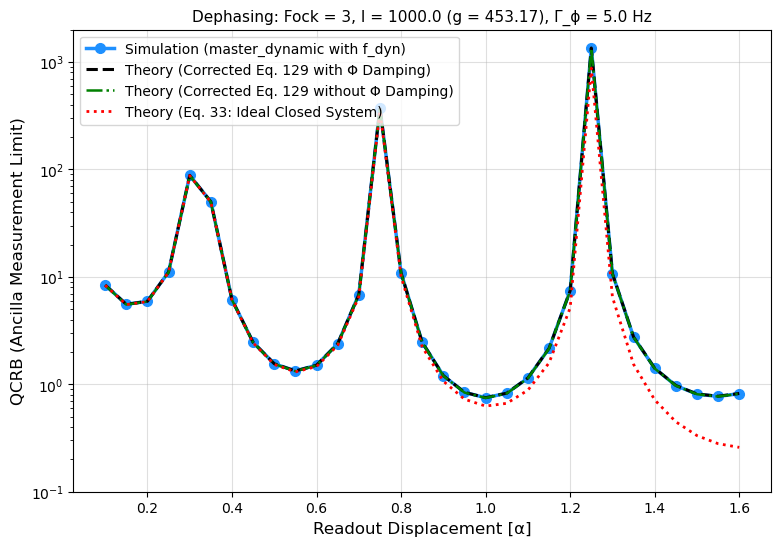


Sweeping α (running master_dynamic with f_dyn on each α-displaced state)...


In [16]:
plot_qcrb_results_dephasing(3, 1e3, 5.0)